# Pronóstico de demanda con XGBoost — Los Finos ERP

## A. Objetivo y alcance

Pronosticar las **unidades vendidas diarias** de los 10 productos durante los **14 días siguientes**, con un único `XGBRegressor` global, y compararlo con una referencia simple.

- **Datos sintéticos** (lote `LF-DEMANDA-V1`): la evaluación demuestra el **método bajo la simulación**; no acredita precisión sobre demanda real.
- El resultado son **productos vendidos previstos**, todavía **no** cantidades de insumos a comprar.
- Configuración **fija** (sin búsqueda de parámetros). La prueba final de octubre **no** se usa para ajustar nada.
- Solo lectura: el cuaderno consulta la vista y escribe archivos en `python/artifacts/demanda/`.

## B. Entorno y carga

In [1]:
import sys
from pathlib import Path

_base = Path.cwd().resolve()
_candidatos = [b / r for b in (_base, *_base.parents) for r in ("src", "python/src")]
_src = next(x for x in _candidatos if (x / "losfinos_demanda").is_dir())
if str(_src) not in sys.path:
    sys.path.insert(0, str(_src))
RAIZ_PY = _src.parent
ARTEFACTOS = RAIZ_PY / "artifacts" / "demanda"
ARTEFACTOS.mkdir(parents=True, exist_ok=True)

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from losfinos_demanda import config, datos, graficos, modelo as m

graficos.estilo()
pd.set_option("display.max_columns", 30, "display.width", 200)
for k, v in m.versiones().items():
    print(f"{k:<13}: {v}")

python       : 3.11.18
pandas       : 3.1.0
numpy        : 2.4.6
xgboost      : 3.2.0
scikit-learn : 1.9.1
joblib       : 1.6.0


In [2]:
engine = config.crear_engine()
config.probar_conexion(engine)
df = datos.cargar_demanda_diaria(engine, datos.LOTE_POR_DEFECTO)

validacion = datos.validar_demanda(df)
datos.exigir_sin_errores(validacion)
print(validacion["Nivel"].value_counts().to_dict(), "| filas:", len(df))

ULTIMO_DIA = df["Fecha"].max()          # último día del dataset; no se usa la fecha del sistema
print("Último día disponible:", ULTIMO_DIA.date())
assert ULTIMO_DIA == pd.Timestamp("2026-10-28")

# El supuesto de disponibilidad futura debe reproducir la disponibilidad observada.
print("Filas históricas que contradicen la regla:", m.verificar_regla(df))
print(m.REGLA.describir())

{'ok': 19, 'info': 1} | filas: 1830
Último día disponible: 2026-10-28
Filas históricas que contradicen la regla: 0
Producto 6 disponible en días pares desde 2026-04-29, producto 7 en días impares; los demás, todos los días.


## C. Variables y modelo

**Variables** (por producto y fecha): `ProductoID` en one-hot, día de la semana, posición temporal (días desde 29/04/2026), `Disponible`, rezagos de ventas de 1, 7, 14 y 28 días y promedios móviles de 7 y 14 días calculados **sobre ventas desplazadas un día** (solo pasado). Los rezagos se calculan por producto y se conservan los ceros; solo se descartan los primeros 28 días de cada producto.

**No se usan** como predictores: `ImporteVendido`, `UnidadesAnuladas`, ventas o totales futuros, compras, saldos, consumos ni identificadores del lote.

**Disponibilidad futura:** para los menús 6 y 7 se asume la alternancia del prototipo anclada al 29/04/2026 (supuesto configurable, `ReglaDisponibilidad`); los demás productos están disponibles todos los días. No se deduce de ventas futuras.

**Modelo:** `XGBRegressor` global con parámetros fijos. Nota: `objective="reg"` no es un objetivo válido en XGBoost; se usa `reg:squarederror`, el regresor estándar.

**Pronóstico recursivo:** tras el primer día, rezagos y promedios usan las predicciones previas; las negativas se recortan a 0 y se fuerza 0 cuando `Disponible=0`.

**Referencia:** promedio de las últimas 4 observaciones disponibles del mismo día de la semana del producto (conocidas en el origen); si hay menos, las existentes; si no hay, el promedio de días disponibles de los últimos 28 días; 0 si el producto no estará disponible.

In [3]:
print(json.dumps(m.PARAMETROS, indent=2))
print(len(m.columnas_variables()), "variables:", m.columnas_variables())
X, y = m.construir_entrenamiento(df, "2026-08-19")
print("Ejemplo de entrenamiento hasta 19/08:", X.shape, "| ceros en y:", int((y == 0).sum()))

{
  "objective": "reg:squarederror",
  "n_estimators": 150,
  "max_depth": 3,
  "learning_rate": 0.05,
  "subsample": 0.9,
  "colsample_bytree": 0.9,
  "random_state": 42,
  "n_jobs": 2
}
19 variables: ['prod_1', 'prod_2', 'prod_3', 'prod_4', 'prod_5', 'prod_6', 'prod_7', 'prod_8', 'prod_9', 'prod_10', 'dia_semana', 'posicion', 'disponible', 'lag_1', 'lag_7', 'lag_14', 'lag_28', 'media_7', 'media_14']
Ejemplo de entrenamiento hasta 19/08: (850, 19) | ceros en y: 96


## D. Validación temporal (dentro del desarrollo: 29/04–30/09/2026)

Tres bloques de 14 días. En cada origen se entrena **solo con fechas hasta ese día** y ambos métodos usan únicamente la historia conocida en ese origen. Orígenes: 19/08, 02/09 y 16/09.

Métricas principales: **MAE** y **WAPE** (Σ|error| / Σ ventas reales); si el denominador es cero se informa `NaN` (no calculable). Como ambos métodos fuerzan 0 en días no disponibles, las métricas *solo días disponibles* son las más informativas.

In [4]:
val = m.evaluar_bloques(df, m.BLOQUES_VALIDACION, "Validación")
def vista(met, alcance="Global"):
    return met[(met["Alcance"] == alcance)].pivot_table(index="Bloque", columns="Metodo", values=["MAE", "WAPE"]).round(3)
print("Global:");                 display(vista(val.metricas))
print("Solo días disponibles:");  display(vista(val.metricas, "Solo días disponibles"))

Global:


MAE               WAPE        
Metodo                  Referencia XGBoost Referencia XGBoost
Bloque                                                       
2026-08-19 → 2026-09-02      2.400   2.302      0.307   0.294
2026-09-02 → 2026-09-16      2.307   2.322      0.335   0.338
2026-09-16 → 2026-09-30      2.146   2.287      0.286   0.305
Todos los bloques            2.285   2.303      0.309   0.311

Solo días disponibles:


MAE               WAPE        
Metodo                  Referencia XGBoost Referencia XGBoost
Bloque                                                       
2026-08-19 → 2026-09-02      2.667   2.558      0.307   0.294
2026-09-02 → 2026-09-16      2.563   2.580      0.335   0.338
2026-09-16 → 2026-09-30      2.385   2.541      0.286   0.305
Todos los bloques            2.538   2.559      0.309   0.311

In [5]:
pp = val.metricas[(val.metricas["Bloque"] == "Todos los bloques") & (val.metricas["Alcance"] == "Por producto (solo disponibles)")]
display(pp.pivot_table(index="ProductoID", columns="Metodo", values=["MAE", "WAPE"]).round(3))

MAE               WAPE        
Metodo     Referencia XGBoost Referencia XGBoost
ProductoID                                      
1               3.024   3.110      0.271   0.278
2               3.893   3.626      0.373   0.348
3               1.548   1.453      0.367   0.345
4               2.833   2.870      0.279   0.282
5               3.012   3.182      0.281   0.297
6               1.786   1.867      0.347   0.363
7               2.071   2.305      0.444   0.494
8               1.893   1.935      0.430   0.439
9               3.536   3.589      0.227   0.230
10              1.179   1.184      0.476   0.478

## E. Prueba final reservada (01/10–28/10/2026)

Dos bloques de 14 días con la configuración fija, **sin cambiar parámetros ni reglas**:

- Origen 30/09 → 01/10–14/10.
- Origen 14/10 → 15/10–28/10, **reentrenando con las ventas ya observadas hasta el 14/10** (actualización quincenal con ventana creciente).

Si XGBoost queda peor que la referencia, se informa tal cual.

In [6]:
prueba = m.evaluar_bloques(df, m.BLOQUES_PRUEBA, "Prueba")
print("Global:");                 display(vista(prueba.metricas))
print("Solo días disponibles:");  display(vista(prueba.metricas, "Solo días disponibles"))
pp = prueba.metricas[(prueba.metricas["Bloque"] == "Todos los bloques") & (prueba.metricas["Alcance"] == "Por producto (solo disponibles)")]
display(pp.pivot_table(index="ProductoID", columns="Metodo", values=["MAE", "WAPE"]).round(3))

Global:


MAE               WAPE        
Metodo                  Referencia XGBoost Referencia XGBoost
Bloque                                                       
2026-09-30 → 2026-10-14      2.529   2.339      0.320   0.296
2026-10-14 → 2026-10-28      2.104   2.158      0.289   0.296
Todos los bloques            2.316   2.248      0.305   0.296

Solo días disponibles:


MAE               WAPE        
Metodo                  Referencia XGBoost Referencia XGBoost
Bloque                                                       
2026-09-30 → 2026-10-14      2.810   2.599      0.320   0.296
2026-10-14 → 2026-10-28      2.337   2.398      0.289   0.296
Todos los bloques            2.573   2.498      0.305   0.296

MAE               WAPE        
Metodo     Referencia XGBoost Referencia XGBoost
ProductoID                                      
1               3.750   3.618      0.302   0.291
2               3.482   3.535      0.329   0.334
3               1.607   1.627      0.409   0.414
4               2.500   2.467      0.233   0.229
5               3.268   2.946      0.313   0.282
6               1.589   1.922      0.332   0.402
7               2.339   2.299      0.449   0.441
8               1.732   1.541      0.462   0.411
9               3.875   3.738      0.235   0.227
10              0.982   0.902      0.387   0.356

### Comparación compacta XGBoost vs referencia

In [7]:
metricas = pd.concat([val.metricas, prueba.metricas], ignore_index=True)
compacta = metricas[(metricas["Bloque"] == "Todos los bloques") & metricas["Alcance"].isin(["Global", "Solo días disponibles"])]
tabla = compacta.pivot_table(index=["Etapa", "Alcance"], columns="Metodo", values=["MAE", "WAPE"]).round(3)
display(tabla)

for etapa in ("Validación", "Prueba"):
    w = compacta[(compacta["Etapa"] == etapa) & (compacta["Alcance"] == "Solo días disponibles")].set_index("Metodo")["WAPE"]
    veredicto = "MEJORA a la referencia" if w["XGBoost"] < w["Referencia"] else "NO mejora a la referencia"
    print(f"{etapa}: WAPE XGBoost {w['XGBoost']:.3f} vs referencia {w['Referencia']:.3f} → XGBoost {veredicto}.")

MAE               WAPE        
Metodo                           Referencia XGBoost Referencia XGBoost
Etapa      Alcance                                                    
Prueba     Global                     2.316   2.248      0.305   0.296
           Solo días disponibles      2.573   2.498      0.305   0.296
Validación Global                     2.285   2.303      0.309   0.311
           Solo días disponibles      2.538   2.559      0.309   0.311

Validación: WAPE XGBoost 0.311 vs referencia 0.309 → XGBoost NO mejora a la referencia.
Prueba: WAPE XGBoost 0.296 vs referencia 0.305 → XGBoost MEJORA a la referencia.


### Observado vs predicho (un producto)

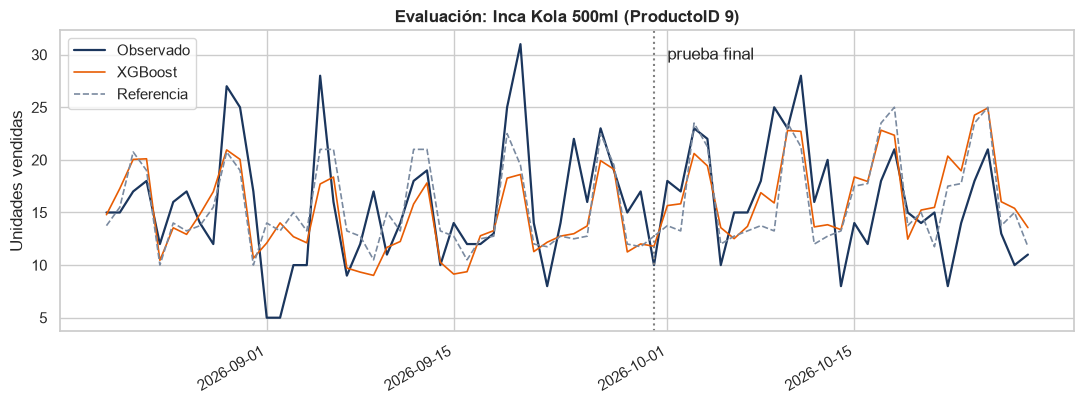

In [8]:
PRODUCTO_GRAFICO = 9   # cambie el ProductoID para ver otro producto
det = pd.concat([val.detalle, prueba.detalle], ignore_index=True)
det = det[det["ProductoID"] == PRODUCTO_GRAFICO]
nombre = det["NombreProducto"].iloc[0]
fig, ax = plt.subplots(figsize=(11, 4.2))
real = det[det["Metodo"] == "XGBoost"].set_index("Fecha")["Real"]
ax.plot(real.index, real.values, color="#1b365d", linewidth=1.6, label="Observado")
for metodo, color in (("XGBoost", "#e85d04"), ("Referencia", "#7a8aa0")):
    s = det[det["Metodo"] == metodo].set_index("Fecha")["Prediccion"]
    ax.plot(s.index, s.values, color=color, linewidth=1.2, linestyle="-" if metodo == "XGBoost" else "--", label=metodo)
ax.axvline(pd.Timestamp("2026-09-30"), color="grey", linestyle=":")
ax.text(pd.Timestamp("2026-10-01"), ax.get_ylim()[1] * 0.95, "prueba final", va="top")
ax.set(title=f"Evaluación: {nombre} (ProductoID {PRODUCTO_GRAFICO})", ylabel="Unidades vendidas")
ax.legend(); fig.autofmt_xdate(); fig.tight_layout(); plt.show()

## F. Pronóstico final

Terminada la evaluación se **reentrena con todo el historial hasta el último día del dataset (28/10/2026)** y se pronostica **29/10–11/11/2026**. Son productos vendidos previstos, no insumos a comprar.

In [9]:
modelo_final = m.entrenar(df, ULTIMO_DIA)
pron = m.pronosticar_xgboost(modelo_final, df, ULTIMO_DIA)

ancho = pron.pivot(index="Fecha", columns="NombreProducto", values="UnidadesPronosticadas").round(1)
display(ancho)

primeros7 = pron[pron["Fecha"] <= ULTIMO_DIA + pd.Timedelta(days=7)]
totales = pd.DataFrame({
    "Primeros 7 días": primeros7.groupby(["ProductoID", "NombreProducto"])["UnidadesPronosticadas"].sum(),
    "14 días": pron.groupby(["ProductoID", "NombreProducto"])["UnidadesPronosticadas"].sum(),
}).round(1)
display(totales)

NombreProducto,Arroz Chaufa Especial de Pollo,Inca Kola 500ml,Jarra de Chicha Morada (1 Litro),Lomo Saltado Criollo,Menú Diario: Estofado de Pollo,Menú Diario: Pollo al Sillao,Mostrito Los Finos,Porción de Alitas Broaster (8 und),Porción de Papas Fritas Familiares,Tallarín Saltado Criollo de Carne
Fecha,,,,,,,,,,
2026-10-29,10.0,13.7,3.7,9.7,0.0,5.3,8.9,9.9,3.4,4.1
2026-10-30,11.1,13.9,5.8,11.9,6.9,0.0,10.7,11.6,2.5,3.9
2026-10-31,13.1,19.5,4.0,15.5,0.0,3.6,16.1,13.9,3.6,4.0
2026-11-01,12.8,20.3,4.4,13.8,3.1,0.0,13.2,14.2,2.7,4.0
2026-11-02,8.0,12.1,3.2,8.6,0.0,5.0,8.5,7.5,2.0,2.8
2026-11-03,7.9,12.4,3.2,8.9,4.2,0.0,7.7,8.1,2.2,3.7
2026-11-04,8.8,12.5,4.4,9.2,0.0,4.7,8.8,8.7,2.3,4.6
2026-11-05,9.9,13.8,3.8,10.6,5.1,0.0,9.6,9.5,2.4,3.9
2026-11-06,11.0,14.5,3.8,13.0,0.0,6.1,11.0,10.9,2.5,5.0


,,Primeros 7 días,14 días
ProductoID,NombreProducto,,
1,Lomo Saltado Criollo,77.5,156.8
2,Arroz Chaufa Especial de Pollo,71.8,143.4
3,Tallarín Saltado Criollo de Carne,27.0,55.1
4,Porción de Alitas Broaster (8 und),74.0,147.2
5,Mostrito Los Finos,73.9,148.3
6,Menú Diario: Estofado de Pollo,14.3,31.3
7,Menú Diario: Pollo al Sillao,18.5,32.4
8,Jarra de Chicha Morada (1 Litro),28.8,55.6
9,Inca Kola 500ml,104.3,211.5


## G. Comprobaciones

In [10]:
# 1) Estructura del pronóstico final
assert len(pron) == 140 and not pron.duplicated(["Fecha", "ProductoID"]).any()
fechas_esperadas = pd.date_range(ULTIMO_DIA + pd.Timedelta(days=1), periods=14)
assert list(pron["Fecha"].drop_duplicates()) == list(fechas_esperadas)
assert pron["Fecha"].min() == pd.Timestamp("2026-10-29") and pron["Fecha"].max() == pd.Timestamp("2026-11-11")
assert (pron.groupby("Fecha")["ProductoID"].nunique() == 10).all()
# 2) Valores finitos, no negativos y cero cuando no hay disponibilidad
assert np.isfinite(pron["UnidadesPronosticadas"]).all() and (pron["UnidadesPronosticadas"] >= 0).all()
assert (pron.loc[pron["Disponible"] == 0, "UnidadesPronosticadas"] == 0).all()
print("OK estructura: 140 filas, sin duplicados, fechas exactas, finitas, >= 0 y cero sin disponibilidad.")

# 3) Alterar ventas posteriores al origen no cambia las predicciones
origen = pd.Timestamp("2026-10-14")
alterado = df.copy()
posterior = alterado["Fecha"] > origen
alterado.loc[posterior, "UnidadesVendidas"] = alterado.loc[posterior, "UnidadesVendidas"] * 7 + 13
mod_o = m.entrenar(df, origen)
pd.testing.assert_frame_equal(m.pronosticar_xgboost(mod_o, df, origen), m.pronosticar_xgboost(mod_o, alterado, origen))
pd.testing.assert_frame_equal(m.pronosticar_referencia(df, origen), m.pronosticar_referencia(alterado, origen))
print("OK sin fuga: ventas posteriores al origen no cambian XGBoost ni la referencia.")

OK estructura: 140 filas, sin duplicados, fechas exactas, finitas, >= 0 y cero sin disponibilidad.
OK sin fuga: ventas posteriores al origen no cambian XGBoost ni la referencia.


## H. Guardado de artefactos

In [11]:
salida = pron[["Fecha", "ProductoID", "NombreProducto", "Disponible", "UnidadesPronosticadas"]].copy()
salida["Fecha"] = salida["Fecha"].dt.strftime("%Y-%m-%d")
salida.to_csv(ARTEFACTOS / "pronostico_14_dias.csv", index=False)
metricas.to_csv(ARTEFACTOS / "metricas.csv", index=False)
m.guardar_modelo(modelo_final, ARTEFACTOS / "modelo_xgboost.joblib")
meta = m.guardar_metadata(ARTEFACTOS / "metadata.json", datos.LOTE_POR_DEFECTO, ULTIMO_DIA,
                          (df["Fecha"].min(), ULTIMO_DIA))

# El modelo guardado reproduce la predicción con las mismas entradas (y las mismas columnas).
paquete = m.cargar_modelo(ARTEFACTOS / "modelo_xgboost.joblib")
rep = m.pronosticar_xgboost(paquete["modelo"], df, ULTIMO_DIA)
pd.testing.assert_frame_equal(rep, pron)
print("OK modelo guardado reproduce el pronóstico.")
print(sorted(p.name for p in ARTEFACTOS.iterdir()))
print("Variables guardadas:", len(meta["variables"]), "| corte:", meta["fecha_corte"])

OK modelo guardado reproduce el pronóstico.
['metadata.json', 'metricas.csv', 'modelo_xgboost.joblib', 'pronostico_14_dias.csv']
Variables guardadas: 19 | corte: 2026-10-28


## I. Conclusiones y limitaciones

- La tabla comparativa muestra si XGBoost mejoró o no a la referencia **en la simulación**; el veredicto se reporta sin ajustes posteriores sobre octubre.
- Los datos son sintéticos, con ~6 meses de historia y un patrón generado: el resultado **no** acredita precisión sobre demanda real.
- El pronóstico final depende del supuesto de alternancia de los menús 6 y 7; si el negocio la cambia, hay que actualizar `ReglaDisponibilidad`.
- `modelo_xgboost.joblib` **no basta por sí solo**: para predecir hace falta la historia reciente de ventas (rezagos de hasta 28 días).
- El resultado son productos vendidos previstos; convertirlos en **necesidades de insumos** (recetas, stock, abastecimientos pendientes) es la siguiente etapa, junto con evaluar algoritmos alternativos.